<a href="https://colab.research.google.com/github/akshaybhatt97/365-DAYS-AI-ML-WITH-AKSHAY/blob/main/day_103_causal_masking.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Day 103/365 — Causal Masking: How GPT Stops Itself From Seeing the Future

Yesterday we compared **Encoder vs Decoder Transformers**.

Today we focus on one rule that makes decoder-only Transformers work correctly:

**When predicting the next token, the model must not see future tokens.**

That is the purpose of **causal masking**.

We demonstrate it on a real sequential dataset by training two identical decoder-style Transformers:

1. one without a mask
2. one with a causal mask

This becomes a practical example of **future leakage**.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error
from statsmodels.datasets import sunspots


## 1. Prepare the real sunspot sequence dataset

In [2]:
data = sunspots.load_pandas().data.copy()

years = data["YEAR"].astype(int).values

values = (
    data["SUNACTIVITY"]
    .astype(np.float32)
    .values
    .reshape(-1,1)
)

split = int(len(values) * 0.8)

scaler = MinMaxScaler()
scaler.fit(values[:split])

scaled = scaler.transform(values)

sequence_length = 12

X = []
y_sequence = []
y_next = []

for i in range(len(scaled) - sequence_length):

    X.append(
        scaled[i:i+sequence_length]
    )

    y_sequence.append(
        scaled[i+1:i+sequence_length+1]
    )

    y_next.append(
        scaled[i+sequence_length]
    )

X = np.array(X,dtype=np.float32)
y_sequence = np.array(y_sequence,dtype=np.float32)
y_next = np.array(y_next,dtype=np.float32)

target_indices = np.arange(
    sequence_length,
    len(scaled)
)

train_mask = target_indices < split
test_mask = target_indices >= split

X_train = X[train_mask]
X_test = X[test_mask]

y_train_sequence = y_sequence[train_mask]
y_test_sequence = y_sequence[test_mask]
y_test_next = y_next[test_mask]


In [3]:
train_loader = DataLoader(
    TensorDataset(
        torch.tensor(X_train),
        torch.tensor(y_train_sequence)
    ),
    batch_size=32,
    shuffle=True
)


## 2. Why leakage happens

Suppose:

`[x1, x2, x3, x4]`

is the input sequence.

And every position predicts the next value:

`x1 → x2`

`x2 → x3`

`x3 → x4`

If position 1 is allowed to attend to position 2 while predicting `x2`, the answer is already visible.

That is future leakage.


## 3. Causal mask

For four positions:

```text
1 0 0 0
1 1 0 0
1 1 1 0
1 1 1 1
```

A position may attend only to itself and earlier positions.


In [4]:
def create_causal_mask(
    sequence_length
):

    mask = torch.full(
        (
            sequence_length,
            sequence_length
        ),
        float("-inf")
    )

    return torch.triu(
        mask,
        diagonal=1
    )

print(
    create_causal_mask(4)
)


tensor([[0., -inf, -inf, -inf],
        [0., 0., -inf, -inf],
        [0., 0., 0., -inf],
        [0., 0., 0., 0.]])


## 4. Build the decoder-style Transformer

In [5]:
class DecoderForecaster(nn.Module):

    def __init__(
        self,
        use_causal_mask=True,
        d_model=12,
        heads=3
    ):
        super().__init__()

        self.use_causal_mask = (
            use_causal_mask
        )

        self.input_projection = nn.Linear(
            1,
            d_model
        )

        self.position = nn.Parameter(
            torch.randn(
                1,
                sequence_length,
                d_model
            ) * 0.02
        )

        self.attention = nn.MultiheadAttention(
            d_model,
            heads,
            batch_first=True
        )

        self.norm1 = nn.LayerNorm(
            d_model
        )

        self.feed_forward = nn.Sequential(
            nn.Linear(d_model,24),
            nn.ReLU(),
            nn.Linear(24,d_model)
        )

        self.norm2 = nn.LayerNorm(
            d_model
        )

        self.output = nn.Linear(
            d_model,
            1
        )

    def forward(self,x):

        z = (
            self.input_projection(x)
            + self.position
        )

        attention_mask = None

        if self.use_causal_mask:

            attention_mask = torch.full(
                (
                    sequence_length,
                    sequence_length
                ),
                float("-inf"),
                device=x.device
            )

            attention_mask = torch.triu(
                attention_mask,
                diagonal=1
            )

        attention_output, _ = (
            self.attention(
                z,
                z,
                z,
                attn_mask=attention_mask,
                need_weights=False
            )
        )

        z = self.norm1(
            z + attention_output
        )

        z = self.norm2(
            z + self.feed_forward(z)
        )

        return self.output(z)


## 5. Train one masked and one unmasked model

In [6]:
def train_model(
    use_causal_mask,
    epochs=30
):

    torch.manual_seed(42)

    model = DecoderForecaster(
        use_causal_mask=use_causal_mask
    )

    criterion = nn.MSELoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.003
    )

    losses = []

    for epoch in range(epochs):

        model.train()

        total_loss = 0
        total_samples = 0

        for xb, yb in train_loader:

            optimizer.zero_grad()

            prediction = model(xb)

            loss = criterion(
                prediction,
                yb
            )

            loss.backward()

            optimizer.step()

            total_loss += (
                loss.item() * len(xb)
            )

            total_samples += len(xb)

        losses.append(
            total_loss / total_samples
        )

    return model, losses


causal_model, causal_losses = (
    train_model(True)
)

open_model, open_losses = (
    train_model(False)
)


## 6. Compare training loss

The unmasked model may achieve a deceptively low loss because future sequence positions are visible.

This is not the kind of information the model would have during real generation.


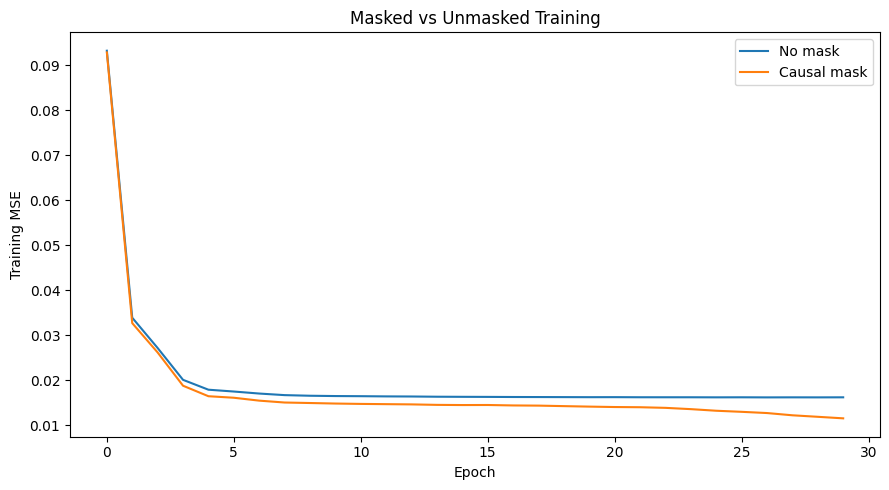

In [7]:
plt.figure(figsize=(9,5))

plt.plot(
    open_losses,
    label="No mask"
)

plt.plot(
    causal_losses,
    label="Causal mask"
)

plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title(
    "Masked vs Unmasked Training"
)

plt.legend()
plt.tight_layout()
plt.show()


## 7. Evaluate the true next unseen step

The last prediction is the cleanest test.

Its target comes after the complete input sequence, so the true answer is not present in the context.


In [8]:
causal_model.eval()
open_model.eval()

with torch.no_grad():

    causal_predictions = (
        causal_model(
            torch.tensor(X_test)
        ).numpy()
    )

    open_predictions = (
        open_model(
            torch.tensor(X_test)
        ).numpy()
    )

actual_next = scaler.inverse_transform(
    y_test_next
)

causal_final = scaler.inverse_transform(
    causal_predictions[:, -1, :]
)

open_final = scaler.inverse_transform(
    open_predictions[:, -1, :]
)

causal_mae = mean_absolute_error(
    actual_next.ravel(),
    causal_final.ravel()
)

open_mae = mean_absolute_error(
    actual_next.ravel(),
    open_final.ravel()
)

print(
    "Causal final-step MAE:",
    round(causal_mae,2)
)

print(
    "No-mask final-step MAE:",
    round(open_mae,2)
)


Causal final-step MAE: 20.85
No-mask final-step MAE: 26.66


## 8. Connection to GPT

GPT-style language models are trained with next-token prediction.

For a sequence such as:

`The sky is blue`

the model learns many shifted predictions in parallel.

But when predicting a token at position `t`, causal masking ensures that positions after `t` are invisible.

So the model cannot cheat by looking at the answer.


## 9. Causal masking vs padding masking

They solve different problems.

### Causal mask

Blocks **future positions**.

### Padding mask

Blocks artificial padding tokens such as `<PAD>`.

Both may be used in the same model.


## Simple takeaway

Without causal masking:

**the decoder can accidentally see future information.**

With causal masking:

**position `t` can only use positions ≤ `t`.**

> **Causal masking is what makes autoregressive next-token prediction honest.**


## References

- Attention Is All You Need:
  https://arxiv.org/abs/1706.03762

- GPT-2:
  https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf

- PyTorch MultiheadAttention:
  https://pytorch.org/docs/stable/generated/torch.nn.MultiheadAttention.html
